# Introduction to Distributions

Companion notebook for the [introduction note](../../notes/random_variables_and_distributions/introduction_to_distributions.md) and its [exercises](../../exercises/random_variables_and_distributions/introduction_to_distributions.md).

A random variable assigns a number to each outcome. Its distribution is described by

* a **PMF** $p_X(x)=P(X=x)$ for discrete variables,
* a **PDF** $f_X(x)$ for continuous variables, with $P(a\le X\le b)=\int_a^bf_X(x)\,dx$,
* a **CDF** $F_X(x)=P(X\le x)$ for both.

This notebook builds each of these for dice and normal examples, using only numpy, scipy and matplotlib.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from scipy.integrate import quad

rng = np.random.default_rng(42)

## PMF of a discrete random variable

Take $X$ to be the number on a fair die. The PMF is flat, $1/6$ per face, and must sum to 1. For two dice, the joint PMF is flat on a $6\times6$ grid ($1/36$ each) and summing along one axis recovers the marginal PMF of a single die.

sum of PMF: 1.0
marginal of the joint equals single-die PMF: True


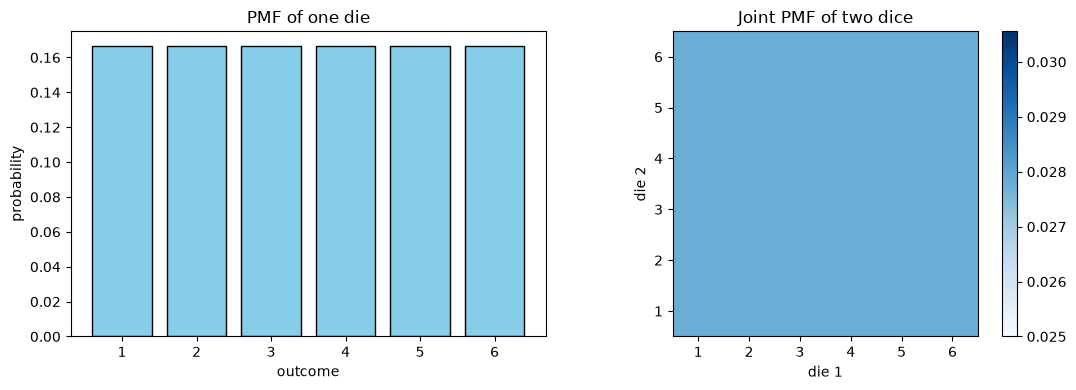

In [2]:
outcomes = np.arange(1, 7)
pmf_die = np.full(6, 1 / 6)
joint = np.full((6, 6), 1 / 36)

print("sum of PMF:", pmf_die.sum().round(10))
print("marginal of the joint equals single-die PMF:", np.allclose(joint.sum(axis=1), pmf_die))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(outcomes, pmf_die, color="skyblue", edgecolor="black")
ax[0].set(title="PMF of one die", xlabel="outcome", ylabel="probability")
im = ax[1].imshow(joint, origin="lower", extent=(0.5, 6.5, 0.5, 6.5), cmap="Blues")
ax[1].set(title="Joint PMF of two dice", xlabel="die 1", ylabel="die 2")
plt.colorbar(im, ax=ax[1])
plt.tight_layout()
plt.show()

## A distribution derived from a random variable: the sum of two dice

Let $S$ be the sum of two fair dice. Counting outcomes gives $P(S=s)=(6-|s-7|)/36$. A seeded simulation of 100,000 throws reproduces this PMF.

P(S = 7) = 0.1667  sum: 1.0


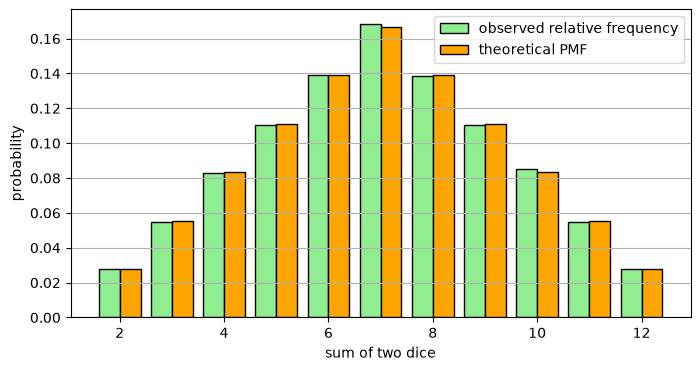

In [3]:
s_values = np.arange(2, 13)
pmf_sum = (6 - np.abs(s_values - 7)) / 36
print("P(S = 7) =", pmf_sum[s_values == 7][0].round(4), " sum:", pmf_sum.sum())

throws = rng.integers(1, 7, size=(100_000, 2)).sum(axis=1)
freq = np.bincount(throws, minlength=13)[2:] / throws.size

plt.figure(figsize=(8, 4))
plt.bar(s_values - 0.2, freq, width=0.4, label="observed relative frequency", color="lightgreen", edgecolor="black")
plt.bar(s_values + 0.2, pmf_sum, width=0.4, label="theoretical PMF", color="orange", edgecolor="black")
plt.xlabel("sum of two dice")
plt.ylabel("probability")
plt.legend()
plt.grid(axis="y")
plt.show()

## Probabilities and expected value from a PMF table

The note's example: a pmf on $1,\dots,10$. Probabilities of events are sums of PMF entries, and $E[X]=\sum x\,p(x)$, $\operatorname{Var}(X)=E[X^2]-E[X]^2$.

In [4]:
x = np.arange(1, 11)
p = np.array([0.05, 0.10, 0.15, 0.20, 0.15, 0.10, 0.08, 0.07, 0.05, 0.05])
assert np.isclose(p.sum(), 1.0)

mean = (x * p).sum()
var = (x**2 * p).sum() - mean**2
print(f"P(X >= 8) = {p[x >= 8].sum():.2f}")
print(f"E[X] = {mean:.3f}, Var(X) = {var:.3f}, mode = {x[p.argmax()]}")

# Die rolled until a 6 appears: P(X = k) = (5/6)^(k-1) / 6
k = np.arange(1, 7)
geo = (5 / 6) ** (k - 1) / 6
print("P(X<=3) =", geo[:3].sum().round(4), " P(X>=3) =", (5 / 6) ** 2)

P(X >= 8) = 0.17
E[X] = 4.920, Var(X) = 5.594, mode = 4
P(X<=3) = 0.4213  P(X>=3) = 0.6944444444444445


## CDF of a discrete variable

The CDF of the die is a right-continuous step function with jumps of $1/6$. It is non-decreasing, starts at 0 and ends at 1.

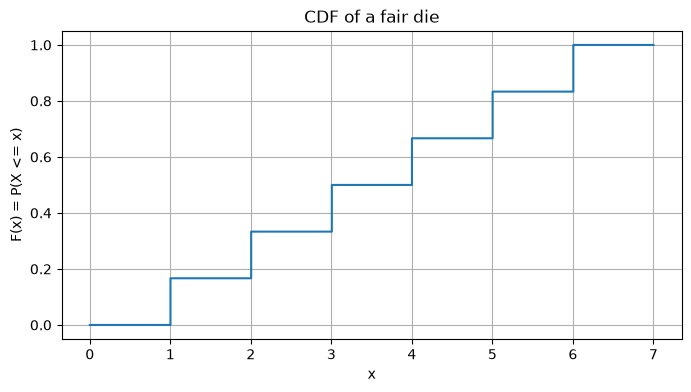

F(3) = 0.5  F(3.5) = 0.5


In [5]:
grid = np.linspace(0, 7, 1000)
cdf_die = np.clip(np.floor(grid) / 6, 0, 1)

plt.figure(figsize=(8, 4))
plt.plot(grid, cdf_die, drawstyle="steps-post")
plt.xlabel("x")
plt.ylabel("F(x) = P(X <= x)")
plt.title("CDF of a fair die")
plt.grid(True)
plt.show()
print("F(3) =", cdf_die[np.searchsorted(grid, 3.0)].round(4), " F(3.5) =", cdf_die[np.searchsorted(grid, 3.5)].round(4))

## PDF and CDF of a continuous variable

For $N(0,1)$ the PDF value at a point is a density, not a probability. The probability of an interval is the area under the PDF, which equals a difference of the CDF. Both approaches agree below. A density can exceed 1: $N(0,0.1^2)$ has peak height about 3.99.

integral of pdf over [-1.0, 2.0] = 0.81859
F(b) - F(a)                  = 0.81859
peak density of N(0, 0.1^2): 3.989
P(X = 0) for a continuous variable is 0; P(|X| < 0.001) = 0.0008


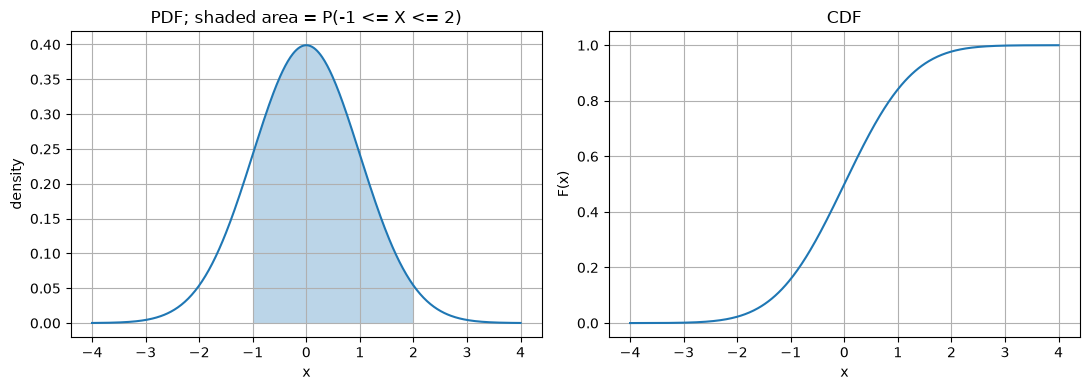

In [6]:
a, b = -1.0, 2.0
area, _ = quad(stats.norm.pdf, a, b)
print(f"integral of pdf over [{a}, {b}] = {area:.5f}")
print(f"F(b) - F(a)                  = {stats.norm.cdf(b) - stats.norm.cdf(a):.5f}")
print("peak density of N(0, 0.1^2):", stats.norm.pdf(0, 0, 0.1).round(3))
print("P(X = 0) for a continuous variable is 0; P(|X| < 0.001) =", (stats.norm.cdf(0.001) - stats.norm.cdf(-0.001)).round(5))

x_c = np.linspace(-4, 4, 500)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(x_c, stats.norm.pdf(x_c))
ax[0].fill_between(x_c, stats.norm.pdf(x_c), where=(x_c >= a) & (x_c <= b), alpha=0.3)
ax[0].set(title="PDF; shaded area = P(-1 <= X <= 2)", xlabel="x", ylabel="density")
ax[1].plot(x_c, stats.norm.cdf(x_c))
ax[1].set(title="CDF", xlabel="x", ylabel="F(x)")
for axis in ax:
    axis.grid(True)
plt.tight_layout()
plt.show()

## Joint density of two variables

A bivariate normal with independent standard normal components has a joint PDF that is the product of the marginals. The volume under the surface is 1 (checked here by a Riemann sum).

max |joint - product of marginals| = 5.551115123125783e-17
volume under joint PDF ~ 0.9999


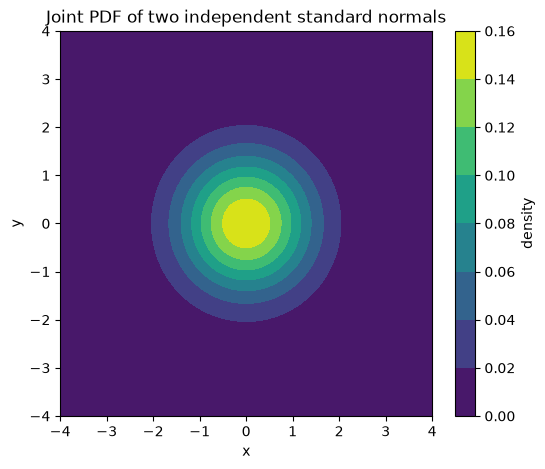

In [7]:
g = np.linspace(-4, 4, 161)
xx, yy = np.meshgrid(g, g)
joint_pdf = stats.multivariate_normal([0, 0], np.eye(2)).pdf(np.dstack((xx, yy)))
product = stats.norm.pdf(xx) * stats.norm.pdf(yy)

step = g[1] - g[0]
print("max |joint - product of marginals| =", np.abs(joint_pdf - product).max())
print("volume under joint PDF ~", (joint_pdf.sum() * step**2).round(4))

plt.figure(figsize=(6, 5))
plt.contourf(xx, yy, joint_pdf)
plt.colorbar(label="density")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Joint PDF of two independent standard normals")
plt.show()

## Takeaways

* A PMF gives probabilities directly and sums to 1; a PDF gives densities and integrates to 1.
* The CDF works for both: $P(a<X\le b)=F(b)-F(a)$.
* Observed relative frequencies converge to the theoretical PMF as the number of trials grows.